# Conflict-free order selection with QAOA

**Tech 5 — Quantum Computing • Project notebook**

A workshop receives more orders than it can process. Each order brings a profit, and some orders
conflict because they need the same machine, the same worker or the same time slot.
We want to accept the most profitable set of orders that contains no conflict.

This notebook follows the modeling chain of the module, one section per step:

| § | Step | What it produces |
|---|------|------------------|
| 0 | Setup & instance | The single instance and the quality metrics used everywhere |
| 1 | Industry problem | Decisions, objective, rule |
| 2 | Mathematical model | Constrained binary program |
| 3 | QUBO | Unconstrained objective $f(x)$ |
| 4 | Cost Hamiltonian | Pauli operator $H_C$ + offset |
| 5 | Exhaustive search | Ground truth and random baseline |
| 6 | QAOA (emulator) | Distribution over solutions + `run_qaoa` |
| 7 | Critical analysis | Effect of layers, penalty weight and problem size |
| 8 | Real hardware | Effect of noise and of the chip topology |
| 9 | Conclusion | What the results do and do not show |

Each section ends with a check against the previous one, so an error is located at the step where it happens.

## 0. Setup and instance

Everything downstream reads the instance from this section, so the exhaustive search and QAOA always
solve the same problem.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q qiskit qiskit-optimization qiskit-aer qiskit-ibm-runtime networkx matplotlib pylatexenc

In [2]:
import itertools
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_optimization.converters import (
    InequalityToEquality,
    IntegerToBinary,
    LinearEqualityToPenalty,
    QuadraticProgramToQubo,
)
from qiskit_optimization.minimum_eigensolvers import QAOA, NumPyMinimumEigensolver
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.utils import algorithm_globals

SEED = 42
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)

In [3]:
# Orders are numbered 1..8 in the text; Python indices are 0..7.
PROFITS = [5, 3, 4, 6, 2, 5, 3, 4]
CONFLICTS_1BASED = [(1, 2), (1, 3), (2, 4), (3, 4), (3, 5), (4, 6), (5, 6), (5, 7), (6, 8), (7, 8)]
CONFLICTS = [(i - 1, j - 1) for i, j in CONFLICTS_1BASED]
N = len(PROFITS)
A = 7  # penalty weight, justified in section 3

INSTANCE = {"profits": PROFITS, "conflicts": CONFLICTS}

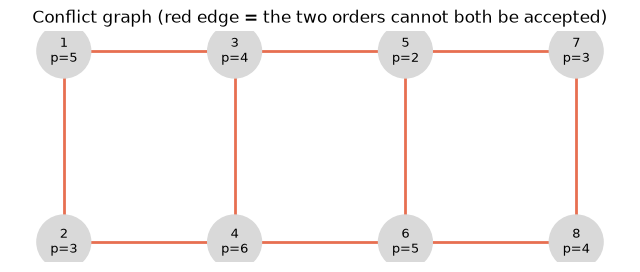

In [4]:
def conflict_graph(profits, conflicts):
    g = nx.Graph()
    g.add_nodes_from(range(len(profits)))
    g.add_edges_from(conflicts)
    return g


def draw_instance(profits, conflicts, selected=None, ax=None, title=None):
    g = conflict_graph(profits, conflicts)
    # Ladder layout: odd orders on the top rail, even orders on the bottom rail.
    pos = {i: (i // 2, -(i % 2)) for i in range(len(profits))} if len(profits) == 8 else nx.spring_layout(g, seed=SEED)
    selected = set(selected or [])
    colors = ["#2a9d8f" if i in selected else "#d9d9d9" for i in g.nodes]
    labels = {i: f"{i + 1}\np={profits[i]}" for i in g.nodes}
    ax = ax or plt.gca()
    nx.draw_networkx(g, pos, ax=ax, labels=labels, node_color=colors, node_size=1500,
                     font_size=9, edge_color="#e76f51", width=2)
    ax.set_title(title or "Conflict graph (red edge = the two orders cannot both be accepted)")
    ax.axis("off")


plt.figure(figsize=(8, 3))
draw_instance(PROFITS, CONFLICTS)
plt.show()

### Quality metrics

QAOA returns a probability distribution over assignments, not a single answer. We judge it with three
numbers, defined once here and reused in every section:

- **P(optimum)**: probability of measuring the optimal assignment.
- **Valid rate**: probability of measuring an assignment with no conflict.
- **Approximation ratio**: expected profit of a measurement divided by the optimal profit.
  An invalid assignment counts as profit 0, since that plan cannot be executed.

In [1]:
def profit(x, profits):
    return sum(p for p, xi in zip(profits, x) if xi)


def is_valid(x, conflicts):
    return all(not (x[i] and x[j]) for i, j in conflicts)


def metrics(distribution, profits, conflicts, best_profit):
    # distribution: {assignment tuple: probability}
    p_opt = valid = expected = 0.0
    for x, prob in distribution.items():
        if is_valid(x, conflicts):
            valid += prob
            expected += prob * profit(x, profits)
            if profit(x, profits) == best_profit:
                p_opt += prob
    return {"P(optimum)": p_opt, "valid rate": valid, "approx. ratio": expected / best_profit}

## 1. Industry problem

**Context.** A workshop receives more orders than it can process. Order $i$ yields a profit $p_i$.
Two orders conflict when they need the same scarce resource: a machine, a qualified worker, or a delivery slot.

**Decision.** Which orders do we accept?
**Objective.** Maximize total profit.
**Rule.** Never accept two conflicting orders.

**The underlying problem.** If orders are vertices and conflicts are edges, a valid choice is an
*independent set* of the conflict graph. Maximizing profit is the **Maximum Weight Independent Set (MWIS)**
problem, which is NP-hard: with $n$ orders there are $2^n$ candidate choices.

**Where else MWIS appears.**
- Telecoms: assigning frequencies so that interfering transmitters are never active together.
- Advertising: choosing which mutually exclusive ad placements to sell.
- Logistics: choosing deliveries that do not compete for the same vehicle or dock.
- Finance: selecting non-overlapping projects or trades.

**Scope.** If every conflict came from overlapping time intervals on one machine, the conflict graph
would be an *interval graph* and a polynomial dynamic program (weighted interval scheduling) would solve it exactly.
Our conflicts mix machines, workers and slots, which produces general graphs. That is where the problem is hard.

### Where the conflicts come from

Each order needs some of the workshop's resources. Every resource has **capacity 1** over the planning week:
it can serve only one accepted order. Two orders that need the same resource therefore conflict, and this is
the only source of conflicts.

| Type | Resource | Needed by orders |
|------|----------|------------------|
| Machine | CNC mill | 1, 2 |
| Machine | Laser cutter | 3, 4 |
| Machine | Paint booth | 5, 6 |
| Machine | Lathe | 7, 8 |
| Worker | Certified welder | 1, 3 |
| Worker | Quality inspector | 4, 6 |
| Worker | Electrician | 5, 7 |
| Time slot | Monday dock slot | 2, 4 |
| Time slot | Wednesday dock slot | 3, 5 |
| Time slot | Friday dock slot | 6, 8 |

Ten resources, each shared by two orders, give the ten conflicts. A resource shared by three orders would add
a triangle of conflicts, and our graph has none. Real capacities (machine-hours, several welders) would need
knapsack-type constraints with slack variables, which is a different problem.

The cell below rebuilds the conflict list from this table and checks it against the instance of section 0.

In [6]:
# Capacity 1 per resource: two orders that share one cannot both be accepted.
RESOURCES = {
    "CNC mill": ("machine", [1, 2]),
    "Laser cutter": ("machine", [3, 4]),
    "Paint booth": ("machine", [5, 6]),
    "Lathe": ("machine", [7, 8]),
    "Certified welder": ("worker", [1, 3]),
    "Quality inspector": ("worker", [4, 6]),
    "Electrician": ("worker", [5, 7]),
    "Monday dock slot": ("time slot", [2, 4]),
    "Wednesday dock slot": ("time slot", [3, 5]),
    "Friday dock slot": ("time slot", [6, 8]),
}


def conflicts_from_resources(resources):
    pairs = set()
    for _, orders in resources.values():
        pairs.update(itertools.combinations(sorted(orders), 2))
    return sorted(pairs)


for order in range(1, N + 1):
    needs = [name for name, (_, orders) in RESOURCES.items() if order in orders]
    print(f"Order {order} (p={PROFITS[order - 1]}): {', '.join(needs)}")

assert conflicts_from_resources(RESOURCES) == CONFLICTS_1BASED
print("Conflicts rebuilt from the resources match the instance.")

Order 1 (p=5): CNC mill, Certified welder
Order 2 (p=3): CNC mill, Monday dock slot
Order 3 (p=4): Laser cutter, Certified welder, Wednesday dock slot
Order 4 (p=6): Laser cutter, Quality inspector, Monday dock slot
Order 5 (p=2): Paint booth, Electrician, Wednesday dock slot
Order 6 (p=5): Paint booth, Quality inspector, Friday dock slot
Order 7 (p=3): Lathe, Electrician
Order 8 (p=4): Lathe, Friday dock slot
Conflicts rebuilt from the resources match the instance.


## 2. Mathematical model

**Variables.** $x_i \in \{0, 1\}$, with $x_i = 1$ if order $i$ is accepted.

**Objective.** $\max \sum_i p_i x_i$

**Constraints.** $x_i + x_j \le 1$ for each conflict $(i, j) \in E$.

**Key observation.** For binary variables, $x_i + x_j \le 1 \iff x_i x_j = 0$.
The constraint can therefore be written as a *product* instead of a *sum*. Section 3 relies on this.

We first write the model as it is stated, with linear constraints, in Qiskit.

In [7]:
def build_constrained_model(profits, conflicts):
    qp = QuadraticProgram(name="order_selection")
    for i in range(len(profits)):
        qp.binary_var(f"x{i + 1}")
    qp.maximize(linear={f"x{i + 1}": p for i, p in enumerate(profits)})
    for i, j in conflicts:
        qp.linear_constraint({f"x{i + 1}": 1, f"x{j + 1}": 1}, "<=", 1, name=f"conflict_{i + 1}_{j + 1}")
    return qp


constrained = build_constrained_model(PROFITS, CONFLICTS)
print(constrained.prettyprint())

Problem name: order_selection

Maximize
  5*x1 + 3*x2 + 4*x3 + 6*x4 + 2*x5 + 5*x6 + 3*x7 + 4*x8

Subject to
  Linear constraints (10)
    x1 + x2 <= 1  'conflict_1_2'
    x1 + x3 <= 1  'conflict_1_3'
    x2 + x4 <= 1  'conflict_2_4'
    x3 + x4 <= 1  'conflict_3_4'
    x3 + x5 <= 1  'conflict_3_5'
    x4 + x6 <= 1  'conflict_4_6'
    x5 + x6 <= 1  'conflict_5_6'
    x5 + x7 <= 1  'conflict_5_7'
    x6 + x8 <= 1  'conflict_6_8'
    x7 + x8 <= 1  'conflict_7_8'

  Binary variables (8)
    x1 x2 x3 x4 x5 x6 x7 x8



## 3. QUBO

QAOA needs an **unconstrained** binary objective. We move each constraint into the objective as a penalty
that is zero for a valid assignment and positive otherwise. Using the observation from section 2:

$$
\min_{x \in \{0,1\}^n} \; f(x) = -\sum_i p_i x_i + A \sum_{(i,j) \in E} x_i x_j
$$

**Choosing $A$.** Take an assignment that breaks a conflict $(i, j)$. Removing order $j$ loses at most $p_j \le \max_k p_k$
in profit and removes at least $A$ in penalty. If $A > \max_k p_k$, this always lowers $f$, so no assignment that breaks a conflict can be
optimal. Here $\max_k p_k = 6$, so $A = 7$ is the smallest integer that works.

A larger $A$ is also correct, but it stretches the energy scale and makes the profit differences
relatively smaller. Section 7 measures how much that hurts QAOA.

In [8]:
def build_qubo(profits, conflicts, penalty, scale=1.0):
    # scale divides every coefficient: same minimizer, different energy units (used for QAOA in section 6).
    qubo = QuadraticProgram(name="order_selection_qubo")
    for i in range(len(profits)):
        qubo.binary_var(f"x{i + 1}")
    qubo.minimize(
        linear={f"x{i + 1}": -p / scale for i, p in enumerate(profits)},
        quadratic={(f"x{i + 1}", f"x{j + 1}"): penalty / scale for i, j in conflicts},
    )
    return qubo


qubo = build_qubo(PROFITS, CONFLICTS, A)
print(qubo.prettyprint())

Problem name: order_selection_qubo

Minimize
  7*x1*x2 + 7*x1*x3 + 7*x2*x4 + 7*x3*x4 + 7*x3*x5 + 7*x4*x6 + 7*x5*x6 + 7*x5*x7
  + 7*x6*x8 + 7*x7*x8 - 5*x1 - 3*x2 - 4*x3 - 6*x4 - 2*x5 - 5*x6 - 3*x7 - 4*x8

Subject to
  No constraints

  Binary variables (8)
    x1 x2 x3 x4 x5 x6 x7 x8



### Comparison with Qiskit's converters

Qiskit can also build a QUBO automatically from the constrained model. Two ways to do it:

1. **Step-by-step pipeline** (as in notebook 2): `InequalityToEquality` → `IntegerToBinary` → `LinearEqualityToPenalty`.
   Each inequality gets a slack variable $s_{ij}$ so that $x_i + x_j + s_{ij} = 1$.
2. **`QuadraticProgramToQubo`**: it recognizes $x_i + x_j \le 1$ and applies the same product trick
   as our hand-built QUBO (`LinearInequalityToPenalty`), but chooses its own penalty value.

In [9]:
staged = InequalityToEquality().convert(constrained)
staged = IntegerToBinary().convert(staged)
staged_penalty = LinearEqualityToPenalty()
staged = staged_penalty.convert(staged)

auto_converter = QuadraticProgramToQubo()
auto = auto_converter.convert(constrained)

exact_solver = MinimumEigenOptimizer(NumPyMinimumEigensolver())
rows = [
    ("Step-by-step (slack)", staged, staged_penalty.penalty),
    ("QuadraticProgramToQubo", auto, auto_converter.penalty),
    ("Hand-built", qubo, A),
]
print(f"{'QUBO':<24}{'variables':>10}{'penalty':>10}   optimum (x1..x8)")
for name, model, pen in rows:
    res = exact_solver.solve(model)
    print(f"{name:<24}{model.get_num_vars():>10}{pen:>10.0f}   {res.x[:N].astype(int)}")

QUBO                     variables   penalty   optimum (x1..x8)


Step-by-step (slack)            18        33   [1 0 0 1 1 0 0 1]
QuadraticProgramToQubo           8       363   [1 0 0 1 1 0 0 1]
Hand-built                       8         7   [1 0 0 1 1 0 0 1]


**Reading the table.** All three QUBOs have the same optimum. They differ on what matters for hardware:

- The slack pipeline needs **18 qubits** (8 orders + 10 slacks), more than twice as many as necessary.
- The automatic converter uses 8 qubits but picks a very large penalty (a safe bound computed from the objective),
  which crushes the profit differences into a tiny fraction of the energy range.
- The hand-built QUBO uses 8 qubits and the smallest valid penalty.

**→ Next step:** an unconstrained objective $f(x)$, which section 4 turns into a Hamiltonian.

## 4. Cost Hamiltonian

**Start from the QUBO of section 3:**

$$
f(x) = -\sum_i p_i x_i + A \sum_{(i,j) \in E} x_i x_j, \qquad x_i \in \{0, 1\}
$$

**Spin variables.** Replace each bit by a spin $s_i \in \{+1, -1\}$ with

$$
x_i = \frac{1 - s_i}{2}
$$

($x_i = 0 \leftrightarrow s_i = +1$, the convention used by Qiskit: bit 0 is the +1 eigenvalue of $Z$).

**Profit term.** Substitute $x_i$ into the linear part:

$$
-p_i x_i = -\frac{p_i}{2} + \frac{p_i}{2}\, s_i
$$

**Conflict term.** Expand the product of two spins:

$$
x_i x_j = \frac{1}{4}\left(1 - s_i - s_j + s_i s_j\right)
\quad\Rightarrow\quad
A\, x_i x_j = \frac{A}{4} - \frac{A}{4}\, s_i - \frac{A}{4}\, s_j + \frac{A}{4}\, s_i s_j
$$

**Collect the terms.** Each order $i$ appears in $d_i$ conflicts (its degree in the conflict graph), so it receives $-\frac{A}{4}$ once per conflict. Summing over all edges:

$$
f(s) = \underbrace{-\frac{1}{2}\sum_i p_i + \frac{A\,|E|}{4}}_{\text{offset}}
\;+\; \sum_i \underbrace{\left(\frac{p_i}{2} - \frac{A\, d_i}{4}\right)}_{h_i} s_i
\;+\; \sum_{(i,j)\in E} \underbrace{\frac{A}{4}}_{J_{ij}} s_i s_j
$$

**Ising Hamiltonian.** Replacing each spin by the Pauli operator $s_i \to Z_i$ gives the cost Hamiltonian

$$
H_C = \sum_i h_i Z_i + \sum_{(i,j)\in E} J_{ij} Z_i Z_j, \qquad \text{with offset as above.}
$$

So the **$Z$ terms mix profit and penalty**: profit pulls an order towards acceptance ($x_i = 1$), and each of its conflicts
pulls it towards rejection ($x_i = 0$). A negative $h_i$ means the conflicts win.
The **$ZZ$ terms** come only from the conflicts, exactly like the edges of Max-Cut.


In [10]:
def hand_hamiltonian(profits, conflicts, penalty):
    n = len(profits)
    degree = [sum(i in edge for edge in conflicts) for i in range(n)]
    terms = [("Z", [i], profits[i] / 2 - penalty * degree[i] / 4) for i in range(n)]
    terms += [("ZZ", [i, j], penalty / 4) for i, j in conflicts]
    offset = -sum(profits) / 2 + penalty * len(conflicts) / 4
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify(), offset


H_hand, offset_hand = hand_hamiltonian(PROFITS, CONFLICTS, A)
H_qiskit, offset_qiskit = qubo.to_ising()

print("Offset  hand:", offset_hand, " | qiskit:", offset_qiskit)
print("Same operator:", (H_hand - H_qiskit).simplify(atol=1e-9).coeffs.size == 1
      and np.allclose((H_hand - H_qiskit).simplify(atol=1e-9).coeffs, 0))
print()
for label, coeff in sorted(zip(H_qiskit.paulis.to_labels(), H_qiskit.coeffs.real), key=lambda t: t[0].count("Z")):
    qubits = [N - 1 - k for k, c in enumerate(label) if c == "Z"]
    print(f"{'Z' * len(qubits):>3} on orders {[q + 1 for q in sorted(qubits)]!s:<8} coefficient {coeff:+.2f}")

Offset  hand: 1.5  | qiskit: 1.5
Same operator: True

  Z on orders [1]      coefficient -1.00
  Z on orders [2]      coefficient -2.00
  Z on orders [3]      coefficient -3.25
  Z on orders [4]      coefficient -2.25
  Z on orders [5]      coefficient -4.25
  Z on orders [6]      coefficient -2.75
  Z on orders [7]      coefficient -2.00
  Z on orders [8]      coefficient -1.50
 ZZ on orders [1, 2]   coefficient +1.75
 ZZ on orders [1, 3]   coefficient +1.75
 ZZ on orders [2, 4]   coefficient +1.75
 ZZ on orders [3, 4]   coefficient +1.75
 ZZ on orders [3, 5]   coefficient +1.75
 ZZ on orders [4, 6]   coefficient +1.75
 ZZ on orders [5, 6]   coefficient +1.75
 ZZ on orders [5, 7]   coefficient +1.75
 ZZ on orders [6, 8]   coefficient +1.75
 ZZ on orders [7, 8]   coefficient +1.75


**Check.** $H_C$ is diagonal: on the basis state $|x\rangle$ its energy plus the offset must equal $f(x)$.
We verify this on all 256 basis states.

In [11]:
def qubo_value(x, profits, conflicts, penalty):
    return -profit(x, profits) + penalty * sum(x[i] * x[j] for i, j in conflicts)


diagonal = H_qiskit.to_matrix(sparse=True).diagonal().real
# Basis index k has bit i = x_i (qubit 0 is the least significant bit).
max_error = max(
    abs(diagonal[k] + offset_qiskit - qubo_value([(k >> i) & 1 for i in range(N)], PROFITS, CONFLICTS, A))
    for k in range(2**N)
)
print("max |<x|H|x> + offset - f(x)| over 256 states:", max_error)

max |<x|H|x> + offset - f(x)| over 256 states: 0.0


**→ Next step:** the operator $H_C$ and its offset. Its lowest-energy basis state is the best order selection.

## 5. Classical baseline: exhaustive search

We evaluate $f(x)$ on all $2^8 = 256$ assignments. This is the ground truth every QAOA result is compared to.

In [12]:
def brute_force(profits, conflicts, penalty):
    rows = []
    for x in itertools.product([0, 1], repeat=len(profits)):
        rows.append({
            "x": x,
            "f": qubo_value(x, profits, conflicts, penalty),
            "valid": is_valid(x, conflicts),
            "orders": [i + 1 for i in range(len(x)) if x[i]],
        })
    rows.sort(key=lambda r: r["f"])
    return rows


t0 = time.perf_counter()
ranking = brute_force(PROFITS, CONFLICTS, A)
bf_time = time.perf_counter() - t0

BEST = ranking[0]
BEST_PROFIT = -BEST["f"]
n_valid = sum(r["valid"] for r in ranking)

print(f"Exhaustive search over {len(ranking)} assignments in {bf_time * 1e3:.1f} ms\n")
print(f"{'rank':<6}{'f(x)':>6}  {'valid':<7}orders")
for k, r in enumerate(ranking[:6], 1):
    print(f"{k:<6}{r['f']:>6}  {str(r['valid']):<7}{r['orders']}")
best_invalid = next(r for r in ranking if not r["valid"])
print(f"\nBest assignment that breaks a conflict: f = {best_invalid['f']}, orders {best_invalid['orders']}")
print(f"Valid assignments: {n_valid} / {len(ranking)}")

Exhaustive search over 256 assignments in 1.3 ms

rank    f(x)  valid  orders
1        -17  True   [1, 4, 5, 8]
2        -15  True   [2, 3, 6, 7]
3        -15  True   [1, 4, 8]
4        -14  True   [1, 4, 7]
5        -13  True   [1, 6, 7]
6        -13  True   [1, 4, 5]

Best assignment that breaks a conflict: f = -12, orders [1, 4, 6, 7]
Valid assignments: 41 / 256


Random guessing: {'P(optimum)': 0.0039, 'valid rate': 0.1602, 'approx. ratio': 0.0804}
NumPyMinimumEigensolver: [1 0 0 1 1 0 0 1] f = -17.0


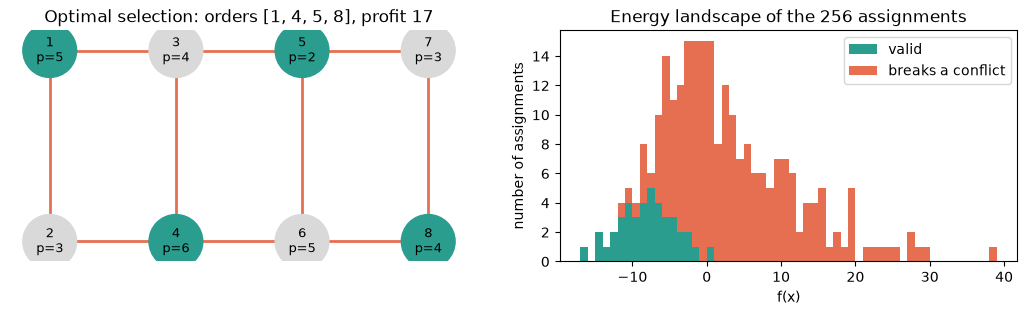

In [13]:
uniform = {r["x"]: 1 / len(ranking) for r in ranking}
RANDOM_BASELINE = metrics(uniform, PROFITS, CONFLICTS, BEST_PROFIT)
print("Random guessing:", {k: round(v, 4) for k, v in RANDOM_BASELINE.items()})

exact = exact_solver.solve(qubo)
print("NumPyMinimumEigensolver:", exact.x.astype(int), "f =", exact.fval)

fig, ax = plt.subplots(1, 2, figsize=(13, 3))
draw_instance(PROFITS, CONFLICTS, selected=[i - 1 for i in BEST["orders"]], ax=ax[0],
              title=f"Optimal selection: orders {BEST['orders']}, profit {BEST_PROFIT}")
f_values = [r["f"] for r in ranking]
ax[1].hist([[r["f"] for r in ranking if r["valid"]], [r["f"] for r in ranking if not r["valid"]]],
           bins=range(min(f_values), max(f_values) + 2), stacked=True, label=["valid", "breaks a conflict"],
           color=["#2a9d8f", "#e76f51"])
ax[1].set_xlabel("f(x)"); ax[1].set_ylabel("number of assignments"); ax[1].legend()
ax[1].set_title("Energy landscape of the 256 assignments")
plt.show()

**Reading the results.**
- The optimum is unique: orders {1, 4, 5, 8}, profit 17.
- Two different selections tie for second place at profit 15, so a QAOA that misses the optimum can still land on a good plan.
- Every assignment that breaks a conflict scores at best $-12$, above many valid ones: the penalty $A = 7$ does its job.
- Only 16 % of assignments are valid. A useful QAOA must beat this random baseline clearly.

**→ Next step:** the true optimum and the random baseline, the two reference points for QAOA.

## 6. QAOA on the emulator

### Workflow

1. **Prepare** $|+\rangle^{\otimes n}$: every assignment equally likely (this is exactly the random baseline).
2. **Evolve** with $p$ layers ("reps"). Layer $k$ applies
   - the **cost layer** $e^{-i\gamma_k H_C}$: an $R_Z$ per Z term and an $R_{ZZ}$ per conflict;
   - the **mixer layer** $e^{-i\beta_k \sum_i X_i}$: an $R_X$ on every qubit.
3. **Measure** all qubits and compute the average energy $\langle H_C \rangle$ from the samples.
4. A **classical optimizer** (COBYLA) updates $(\gamma, \beta)$ to lower $\langle H_C \rangle$, and steps 2–4 repeat.

The quantum computer only evaluates the energy; the classical computer steers the angles.
That is why QAOA is called a *hybrid* algorithm.

### Two practical choices

- **Rescaling.** We divide the QUBO by its largest coefficient ($A$). The optimum is unchanged, but the energy
  is now of order 1, so angles $\gamma \in [0, \pi]$ are a sensible search range. Without it, small changes in $\gamma$ swing
  the phases wildly and COBYLA struggles.
- **Restarts.** COBYLA finds a local minimum of the angle landscape. We run it from several random starting
  points and keep the run with the lowest energy.

In [14]:
def exact_distribution(circuit, n):
    # Exact output probabilities (no shot noise), keyed by assignment tuple (x1..xn).
    probs = Statevector(circuit).probabilities_dict()
    return {tuple(int(b) for b in reversed(bits)): p for bits, p in probs.items() if p > 1e-12}


def run_qaoa(profits, conflicts, penalty, reps, restarts=5, seed=SEED, maxiter=500):
    scale = max(penalty, max(profits))
    model = build_qubo(profits, conflicts, penalty, scale=scale)
    best = None
    start = time.perf_counter()
    for k in range(restarts):
        init = np.random.default_rng(seed + k).uniform(0, np.pi, 2 * reps)
        solver = QAOA(sampler=StatevectorSampler(seed=seed + k), optimizer=COBYLA(maxiter=maxiter),
                      reps=reps, initial_point=init)
        result = MinimumEigenOptimizer(solver).solve(model)
        energy = result.min_eigen_solver_result.optimal_value
        if best is None or energy < best["energy"]:
            mes = result.min_eigen_solver_result
            best = {"energy": energy, "result": result, "params": mes.optimal_point,
                    "circuit": mes.optimal_circuit.remove_final_measurements(inplace=False)
                                                  .assign_parameters(mes.optimal_point)}
    best["time"] = time.perf_counter() - start
    best["distribution"] = exact_distribution(best["circuit"], len(profits))
    return best

In [15]:
REPS = 2
qaoa_run = run_qaoa(PROFITS, CONFLICTS, A, reps=REPS)
qaoa_result = qaoa_run["result"]

print(qaoa_result.prettyprint())
print(f"\nOptimized angles (β then γ): {np.round(qaoa_run['params'], 3)}")
print(f"Run time ({REPS} layers, 5 restarts): {qaoa_run['time']:.1f} s")

objective function value: -2.428571428571429
variable values: x1=1.0, x2=0.0, x3=0.0, x4=1.0, x5=1.0, x6=0.0, x7=0.0, x8=1.0
status: SUCCESS

Optimized angles (β then γ): [ 2.705 -0.178  0.885  3.028]
Run time (2 layers, 5 restarts): 3.4 s


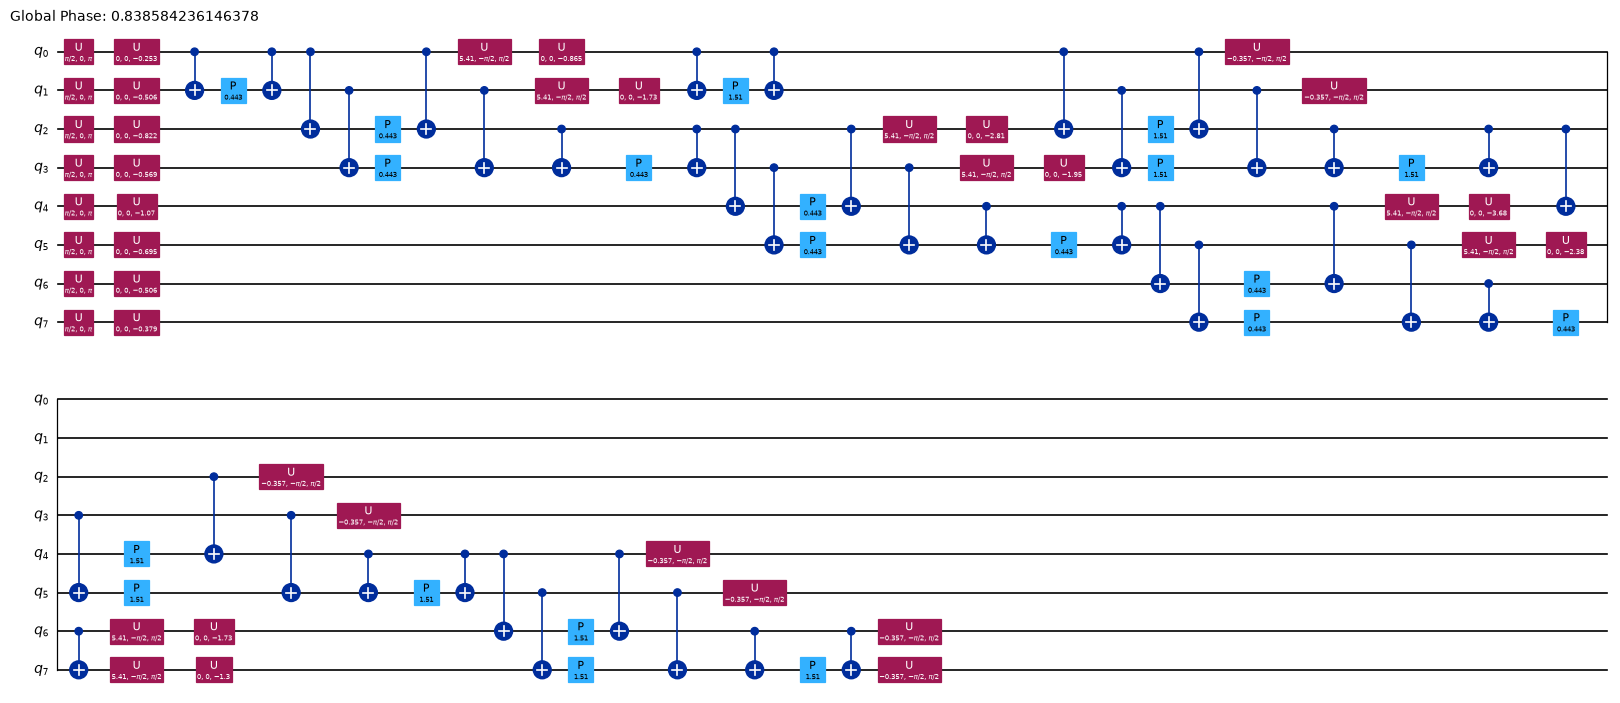

In [16]:
# One layer of the circuit, before transpilation: one RZZ per conflict, one RZ and one RX per order.
qaoa_run["circuit"].decompose(reps=2).draw("mpl", fold=40, scale=0.6)

In [17]:
qaoa_metrics = metrics(qaoa_run["distribution"], PROFITS, CONFLICTS, BEST_PROFIT)

print(f"{'':<18}{'random':>10}{'QAOA':>10}")
for key in qaoa_metrics:
    print(f"{key:<18}{RANDOM_BASELINE[key]:>10.3f}{qaoa_metrics[key]:>10.3f}")
print(f"\nP(optimum) gain over random: x{qaoa_metrics['P(optimum)'] / RANDOM_BASELINE['P(optimum)']:.1f}")

                      random      QAOA
P(optimum)             0.004     0.041
valid rate             0.160     0.779
approx. ratio          0.080     0.507

P(optimum) gain over random: x10.5


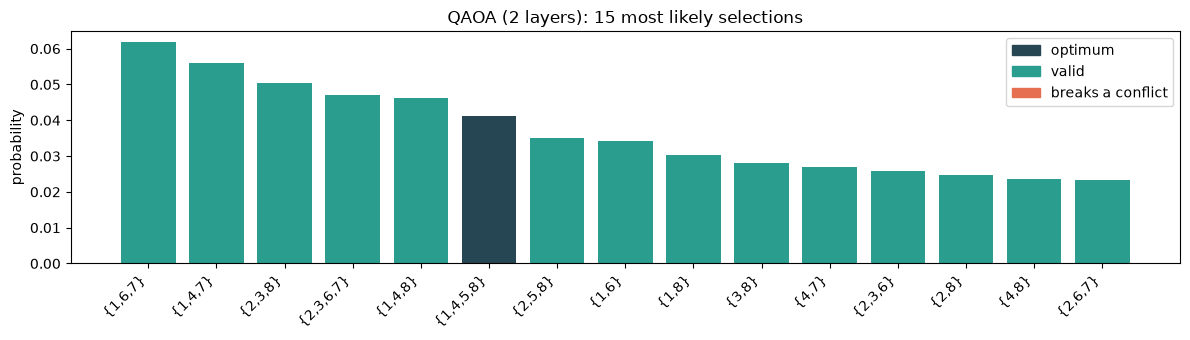

In [18]:
def plot_top(distribution, profits, conflicts, best_profit, k=15, title=""):
    top = sorted(distribution.items(), key=lambda t: -t[1])[:k]
    labels = ["{" + ",".join(str(i + 1) for i, b in enumerate(x) if b) + "}" for x, _ in top]
    colors = ["#264653" if is_valid(x, conflicts) and profit(x, profits) == best_profit
              else "#2a9d8f" if is_valid(x, conflicts) else "#e76f51" for x, _ in top]
    plt.figure(figsize=(12, 3.5))
    plt.bar(labels, [p for _, p in top], color=colors)
    plt.xticks(rotation=45, ha="right"); plt.ylabel("probability"); plt.title(title)
    plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#264653", "#2a9d8f", "#e76f51"]],
               labels=["optimum", "valid", "breaks a conflict"])
    plt.tight_layout(); plt.show()


plot_top(qaoa_run["distribution"], PROFITS, CONFLICTS, BEST_PROFIT,
         title=f"QAOA ({REPS} layers): 15 most likely selections")

**Reading the results.** The objective value above is in rescaled units ($-17/7 \approx -2.43$ means profit 17).
The solution reported by `MinimumEigenOptimizer` is the *best sample*, which is why it can be
optimal even when the optimum is not the most likely outcome. The fairer measures are the metrics above:
QAOA concentrates probability on valid, high-profit selections far more than random guessing, but it is far from
returning the optimum with certainty at this depth.

**→ Next step:** a reusable `run_qaoa(instance, reps, A)` that section 7 sweeps over.

## 7. Critical analysis

Three experiments, all built on `run_qaoa`:

1. **Number of layers** $p$ = 1 … 4 on the main instance.
2. **Penalty weight** $A$ = 7, 10, 20, 363 (the value chosen by `QuadraticProgramToQubo`).
3. **Problem size** $n$ = 4 … 12 orders on random conflict graphs.

### 7.1 Number of layers

In [19]:
layer_rows = []
layer_runs = {}
for reps in [1, 2, 3, 4]:
    run = run_qaoa(PROFITS, CONFLICTS, A, reps=reps)
    layer_runs[reps] = run
    m = metrics(run["distribution"], PROFITS, CONFLICTS, BEST_PROFIT)
    layer_rows.append({"reps": reps, **m, "time (s)": run["time"], "parameters": 2 * reps})

print(f"{'reps':<6}{'P(opt)':>8}{'valid':>8}{'ratio':>8}{'params':>8}{'time (s)':>10}")
for r in layer_rows:
    print(f"{r['reps']:<6}{r['P(optimum)']:>8.3f}{r['valid rate']:>8.3f}{r['approx. ratio']:>8.3f}"
          f"{r['parameters']:>8}{r['time (s)']:>10.1f}")

reps    P(opt)   valid   ratio  params  time (s)
1        0.026   0.650   0.373       2       2.1
2        0.041   0.779   0.507       4       2.8
3        0.026   0.675   0.397       6       4.2
4        0.028   0.759   0.486       8       6.3


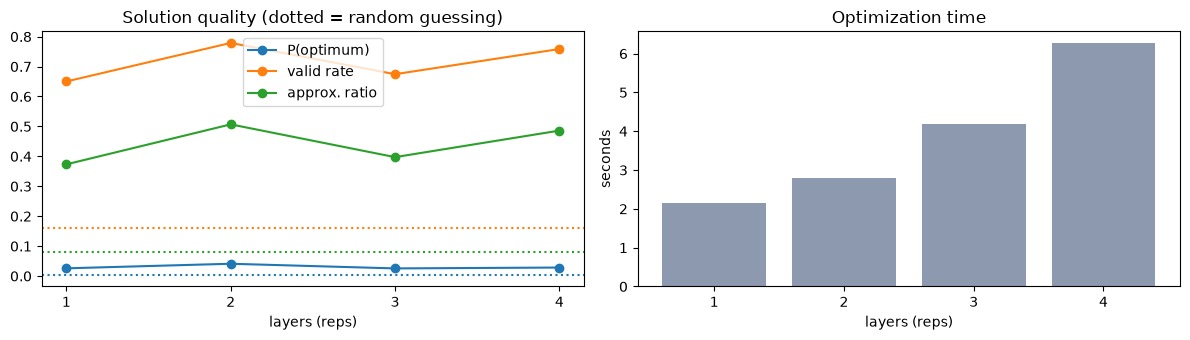

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
reps_axis = [r["reps"] for r in layer_rows]
for key in ["P(optimum)", "valid rate", "approx. ratio"]:
    ax[0].plot(reps_axis, [r[key] for r in layer_rows], "o-", label=key)
    ax[0].axhline(RANDOM_BASELINE[key], ls=":", color=ax[0].lines[-1].get_color())
ax[0].set_xlabel("layers (reps)"); ax[0].set_title("Solution quality (dotted = random guessing)")
ax[0].set_xticks(reps_axis); ax[0].legend()
ax[1].bar(reps_axis, [r["time (s)"] for r in layer_rows], color="#8d99ae")
ax[1].set_xlabel("layers (reps)"); ax[1].set_ylabel("seconds"); ax[1].set_title("Optimization time")
ax[1].set_xticks(reps_axis)
plt.tight_layout(); plt.show()

**What to look for.** In theory, more layers can only help: as $p \to \infty$ QAOA approaches adiabatic evolution
and finds the ground state. In practice each layer adds two angles to optimize and $2|E|$ CNOTs to the circuit,
so the optimizer has a harder job and the hardware accumulates more noise (section 8).
Gains that are not monotonic here come from COBYLA getting stuck in local minima, not from the theory.

### 7.2 Penalty weight

In [21]:
penalty_rows = []
for penalty in [7, 10, 20, auto_converter.penalty]:
    run = run_qaoa(PROFITS, CONFLICTS, penalty, reps=REPS)
    m = metrics(run["distribution"], PROFITS, CONFLICTS, BEST_PROFIT)
    penalty_rows.append({"A": penalty, **m})

print(f"{'A':<8}{'P(opt)':>8}{'valid':>8}{'ratio':>8}")
for r in penalty_rows:
    print(f"{r['A']:<8.0f}{r['P(optimum)']:>8.3f}{r['valid rate']:>8.3f}{r['approx. ratio']:>8.3f}")

A         P(opt)   valid   ratio
7          0.041   0.779   0.507
10         0.032   0.908   0.491
20         0.008   0.832   0.346
363        0.006   0.925   0.382


**What to look for.** All these values of $A$ give the same optimum, so for exhaustive search they are equivalent.
For QAOA they are not. After rescaling, a larger $A$ shrinks the profit terms relative to the penalty:
QAOA still learns to avoid conflicts (valid rate stays high) but can no longer tell good valid plans from
the best one, and P(optimum) drops. The smallest valid penalty is the right default.

### 7.3 Problem size

In [22]:
def random_instance(n, edge_prob=0.35, seed=SEED):
    r = np.random.default_rng(seed + n)
    profits = [int(v) for v in r.integers(1, 7, size=n)]
    conflicts = [(i, j) for i in range(n) for j in range(i + 1, n) if r.random() < edge_prob]
    return profits, conflicts


size_rows = []
for n in [4, 6, 8, 10, 12]:
    profits, conflicts = random_instance(n)
    penalty = max(profits) + 1
    t0 = time.perf_counter()
    ranking_n = brute_force(profits, conflicts, penalty)
    bf = time.perf_counter() - t0
    best_n = -ranking_n[0]["f"]
    run = run_qaoa(profits, conflicts, penalty, reps=REPS, restarts=3)
    m = metrics(run["distribution"], profits, conflicts, best_n)
    n_opt = sum(r["valid"] and -r["f"] == best_n for r in ranking_n)
    size_rows.append({"n": n, "conflicts": len(conflicts), "brute force (s)": bf, "QAOA (s)": run["time"],
                      "random P(opt)": n_opt / 2**n, **m})

print(f"{'n':<4}{'|E|':>5}{'BF (s)':>9}{'QAOA (s)':>10}{'rand P(opt)':>13}{'QAOA P(opt)':>13}{'valid':>8}{'ratio':>8}")
for r in size_rows:
    print(f"{r['n']:<4}{r['conflicts']:>5}{r['brute force (s)']:>9.3f}{r['QAOA (s)']:>10.1f}"
          f"{r['random P(opt)']:>13.4f}{r['P(optimum)']:>13.4f}{r['valid rate']:>8.3f}{r['approx. ratio']:>8.3f}")

n     |E|   BF (s)  QAOA (s)  rand P(opt)  QAOA P(opt)   valid   ratio
4       2    0.000       0.9       0.1250       0.3952   0.973   0.844
6       5    0.000       1.0       0.0156       0.0730   0.685   0.497
8      12    0.001       1.9       0.0078       0.0849   0.776   0.474
10     14    0.004       3.1       0.0020       0.0026   0.231   0.116
12     28    0.020       5.9       0.0002       0.0049   0.589   0.311


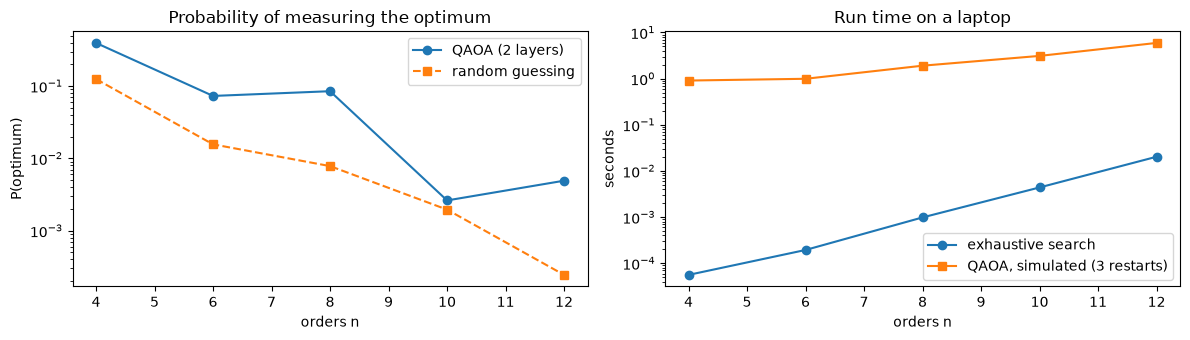

In [23]:
ns = [r["n"] for r in size_rows]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].semilogy(ns, [r["P(optimum)"] for r in size_rows], "o-", label="QAOA (2 layers)")
ax[0].semilogy(ns, [r["random P(opt)"] for r in size_rows], "s--", label="random guessing")
ax[0].set_xlabel("orders n"); ax[0].set_ylabel("P(optimum)"); ax[0].legend()
ax[0].set_title("Probability of measuring the optimum")
ax[1].semilogy(ns, [r["brute force (s)"] for r in size_rows], "o-", label="exhaustive search")
ax[1].semilogy(ns, [r["QAOA (s)"] for r in size_rows], "s-", label="QAOA, simulated (3 restarts)")
ax[1].set_xlabel("orders n"); ax[1].set_ylabel("seconds"); ax[1].legend()
ax[1].set_title("Run time on a laptop")
plt.tight_layout(); plt.show()

**What to look for.**
- Exhaustive search doubles in cost with every extra order ($2^n$). At $n = 50$ it would need about $10^{15}$ evaluations.
- *Simulating* QAOA also grows exponentially (the statevector has $2^n$ amplitudes). This is a property of the
  emulator, not of QAOA. On hardware, one circuit run costs roughly $O(p \cdot |E|)$ gates.
- With a fixed number of layers, P(optimum) falls as $n$ grows, and on some instances QAOA barely beats random guessing.
  Instances of the same size also differ a lot: density and profit ties matter, not only $n$.
  Keeping solution quality constant at larger sizes would need more layers, hence deeper circuits.
- Industrial instances have thousands of orders. Today's devices cannot run QAOA at that scale with useful accuracy,
  while classical MWIS solvers (branch and bound, local search) handle them routinely.

## 8. Real hardware

We do **not** re-optimize the angles on hardware: we reuse the angles found on the emulator (section 6) and only
sample the circuit. This is cheaper, and the comparison then isolates the effect of the hardware itself.

Three settings, same circuit:
1. **Ideal emulator**: exact probabilities from section 6.
2. **Noisy emulator**: `AerSimulator` with the noise model and layout of a real IBM device (`FakeTorino`), available offline.
3. **Real IBM device**: optional, needs an IBM Quantum account. Results are saved to `results/hardware_counts.json`
   so the notebook runs without an account afterwards.

In [24]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeTorino

SHOTS = 4096
measured = qaoa_run["circuit"].copy()
measured.measure_all()

fake_backend = FakeTorino()
pass_manager = generate_preset_pass_manager(optimization_level=3, backend=fake_backend, seed_transpiler=SEED)
isa_circuit = pass_manager.run(measured)


def two_qubit_count(circuit):
    return sum(1 for inst in circuit.data if inst.operation.num_qubits == 2 and inst.operation.name != "barrier")


logical = measured.decompose(reps=3)
print(f"Logical circuit : depth {logical.depth():>4}, two-qubit gates {two_qubit_count(logical):>4}")
print(f"On {fake_backend.name:<11}: depth {isa_circuit.depth():>4}, two-qubit gates {two_qubit_count(isa_circuit):>4}")
print("Physical qubits used:", sorted({isa_circuit.find_bit(q).index for inst in isa_circuit.data
                                       for q in inst.qubits if inst.operation.name == "measure"}))

Logical circuit : depth   36, two-qubit gates   40
On fake_torino: depth  170, two-qubit gates   73
Physical qubits used: [18, 30, 31, 32, 33, 37, 51, 52]


The ladder-shaped conflict graph contains squares (4-cycles), while IBM's heavy-hex layout has none.
Some conflicting orders therefore end up on qubits that are not neighbours on the chip, and the transpiler inserts SWAP
gates to bring them together. The extra two-qubit gates above are the price of the topology.

In [25]:
def counts_to_distribution(counts, n):
    total = sum(counts.values())
    return {tuple(int(b) for b in reversed(bits[-n:])): c / total for bits, c in counts.items()}


noisy_sim = AerSimulator.from_backend(fake_backend, seed_simulator=SEED)
noisy_counts = noisy_sim.run(isa_circuit, shots=SHOTS).result().get_counts()
noisy_distribution = counts_to_distribution(noisy_counts, N)
noisy_metrics = metrics(noisy_distribution, PROFITS, CONFLICTS, BEST_PROFIT)

In [26]:
RUN_ON_HARDWARE = False  # set to True to submit a job (needs a saved IBM Quantum account)
HARDWARE_FILE = Path("results/hardware_counts.json")

if RUN_ON_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N)
    hw_circuit = generate_preset_pass_manager(optimization_level=3, backend=backend,
                                              seed_transpiler=SEED).run(measured)
    job = SamplerV2(mode=backend).run([hw_circuit], shots=SHOTS)
    print("Submitted job", job.job_id(), "on", backend.name)
    hw_counts = job.result()[0].data.meas.get_counts()
    HARDWARE_FILE.parent.mkdir(exist_ok=True)
    HARDWARE_FILE.write_text(json.dumps({"backend": backend.name, "job_id": job.job_id(),
                                         "params": list(map(float, qaoa_run["params"])), "counts": hw_counts}))

hardware_metrics = None
if HARDWARE_FILE.exists():
    saved = json.loads(HARDWARE_FILE.read_text())
    hardware_metrics = metrics(counts_to_distribution(saved["counts"], N), PROFITS, CONFLICTS, BEST_PROFIT)
    print("Loaded hardware results from", saved["backend"], "job", saved["job_id"])
else:
    print("No hardware results yet: set RUN_ON_HARDWARE = True to collect them.")

No hardware results yet: set RUN_ON_HARDWARE = True to collect them.


                          random  ideal emulator  noisy emulator
P(optimum)                 0.004           0.041           0.032
valid rate                 0.160           0.779           0.643
approx. ratio              0.080           0.507           0.407


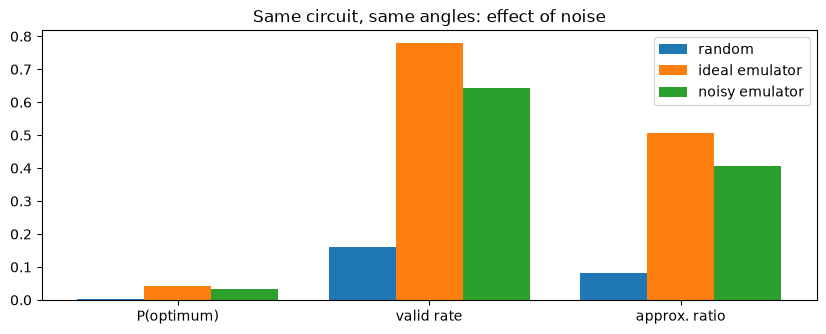

In [27]:
columns = {"random": RANDOM_BASELINE, "ideal emulator": qaoa_metrics, "noisy emulator": noisy_metrics}
if hardware_metrics:
    columns["IBM hardware"] = hardware_metrics

print(f"{'':<16}" + "".join(f"{c:>16}" for c in columns))
for key in qaoa_metrics:
    print(f"{key:<16}" + "".join(f"{col[key]:>16.3f}" for col in columns.values()))

x = np.arange(len(qaoa_metrics))
width = 0.8 / len(columns)
plt.figure(figsize=(10, 3.5))
for k, (name, col) in enumerate(columns.items()):
    plt.bar(x + k * width, list(col.values()), width, label=name)
plt.xticks(x + width * (len(columns) - 1) / 2, list(qaoa_metrics))
plt.legend(); plt.title("Same circuit, same angles: effect of noise"); plt.show()

**What to look for.** Noise (gate errors, decoherence, readout errors) pushes the output distribution back towards
uniform, i.e. towards the random baseline. The valid rate is the most sensitive metric: a single bit flip on a pair of
conflicting orders turns a valid plan into an invalid one. Deeper circuits (more layers, more SWAPs) suffer more,
which is the trade-off against the gains seen in section 7.1.

## 9. Conclusion and limits

**What this notebook shows.**
- A real decision problem (conflict-free order selection) maps cleanly to MWIS, then to a QUBO with
  **one qubit per order**, then to an Ising Hamiltonian whose ZZ terms are the conflicts and whose Z terms mix profit and penalty.
- Modeling choices matter before any quantum code runs: a slack-based conversion needs 18 qubits instead of 8,
  and an oversized penalty hides the profit signal from QAOA.
- On the emulator, QAOA with a few layers concentrates probability on valid, high-profit plans, well above random guessing.

**What it does not show.**
- Any speedup: exhaustive search solves this instance in milliseconds, and classical MWIS heuristics scale far beyond what
  current quantum devices can run.
- That QAOA reliably returns the optimum: P(optimum) stays far below 1 and falls with problem size at fixed depth.

**Possible next steps.** CVaR-QAOA (optimize the best samples instead of the mean energy), warm-start QAOA from a
classical greedy solution, or mixers that only explore valid selections, so the penalty is no longer needed.